# A Century of Portraits: Single-Task vs Multi-Task Learning

This notebook uses the saved, validation-selected checkpoints and the single final test evaluation produced on the TAMU ACES cluster. It does not retrain models or re-evaluate the test split. Seed: **1**; auxiliary task: **gender classification**.

In [1]:
from pathlib import Path
import json
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image
from IPython.display import display

from portrait_mtl import PortraitNet

ROOT = Path.cwd()
ARTIFACTS = ROOT / "artifacts"
RUNS = ROOT / "runs"
FIGURES = ARTIFACTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

metrics = json.loads((ARTIFACTS / "final" / "final_metrics.json").read_text())
selection = json.loads((ARTIFACTS / "model_selection.json").read_text())
predictions = pd.read_csv(ARTIFACTS / "final" / "test_predictions.csv")
metrics

{'protocol': 'Test split evaluated once after validation-only model selection.',
 'dataset_root': '/scratch/user/u.ae271721/midterm_mtl/data/faces_aligned_small_mirrored_co_aligned_cropped_cleaned',
 'audit': {'split': 'test',
  'valid': 7408,
  'excluded': 0,
  'issues': [],
  'year_min': 1905,
  'year_max': 2013,
  'female': 4226,
  'male': 3182},
 'single': {'year_mae': 3.4418882201093832},
 'multi': {'year_mae': 3.4822397417435123,
  'gender_accuracy': 0.9620680345572354,
  'gender_f1': 0.9571972581873572}}

## Dataset and protocol

The official lists contain 29,152 training examples and 7,408 test examples. A seeded 10% validation subset was created from training only. The archive's female split lines contain an undocumented trailing integer; the loader deliberately uses the first whitespace-delimited field as the image path. No listed records were missing or malformed. Images are decoded from a compact SQLite container to avoid ACES inode-quota issues.

In [2]:
audit = json.loads((ARTIFACTS / "data_audit.json").read_text())
audit_table = pd.DataFrame({
    split: {k: v for k, v in values.items() if k not in {"issues", "split"}}
    for split, values in audit.items() if split in {"train", "test"}
}).T
display(audit_table)
print("Selection basis:", selection["selection_basis"])
print("Selected auxiliary weight:", selection["selected_auxiliary_weight"])

,valid,excluded,year_min,year_max,female,male
train,29152,0,1905,2013,15368,13784
test,7408,0,1905,2013,4226,3182


Selection basis: minimum validation year MAE; gender accuracy is tie-breaker
Selected auxiliary weight: 0.05


## Checkpoint reconstruction

The following cell reconstructs each architecture and loads the exact checkpoint selected using validation MAE. This verifies that the saved deliverables are self-contained.

In [3]:
loaded_models = {}
for name, checkpoint_path in {
    "single": RUNS / "single" / "best.pt",
    "multi": RUNS / "multi_0p05" / "best.pt",
}.items():
    checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    model = PortraitNet(checkpoint["config"]["task"], pretrained=False)
    model.load_state_dict(checkpoint["model"])
    model.eval()
    loaded_models[name] = model
    print(f"{name}: epoch {checkpoint['epoch'] + 1}, validation MAE {checkpoint['best_mae']:.3f} years")

single: epoch 20, validation MAE 2.599 years


multi: epoch 20, validation MAE 2.550 years


## Training and validation curves

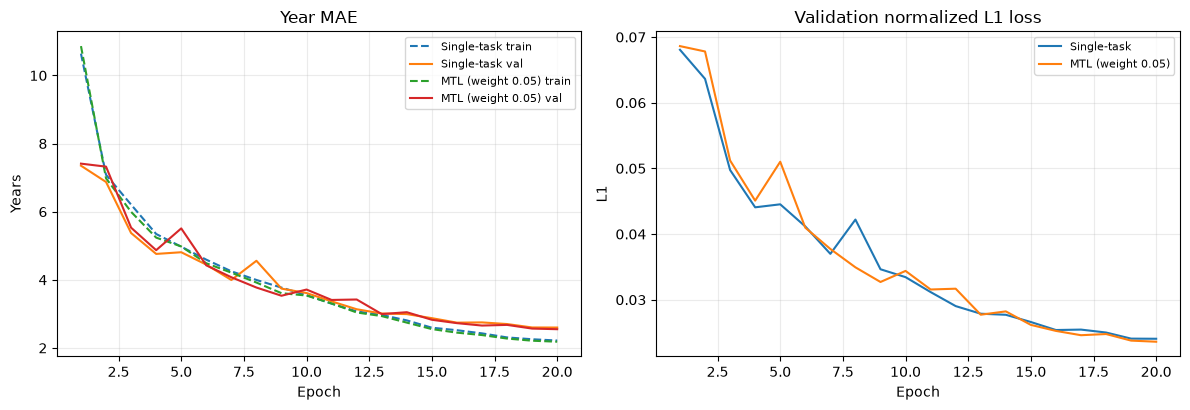

In [4]:
histories = {
    "Single-task": json.loads((RUNS / "single" / "history.json").read_text()),
    "MTL (weight 0.05)": json.loads((RUNS / "multi_0p05" / "history.json").read_text()),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for label, history in histories.items():
    epochs = [row["epoch"] for row in history]
    axes[0].plot(epochs, [row["train"]["year_mae"] for row in history], "--", label=f"{label} train")
    axes[0].plot(epochs, [row["val"]["year_mae"] for row in history], label=f"{label} val")
    axes[1].plot(epochs, [row["val"]["year_loss"] for row in history], label=label)
axes[0].set(title="Year MAE", xlabel="Epoch", ylabel="Years")
axes[1].set(title="Validation normalized L1 loss", xlabel="Epoch", ylabel="L1")
for ax in axes:
    ax.grid(alpha=.25)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "training_curves.png", dpi=180, bbox_inches="tight")
plt.show()

## Validation tuning and final test results

The auxiliary weight was selected before test evaluation. The test split was evaluated once. The better test year MAE is below the assignment's 4-year full-credit threshold. Gender generalization (96.21%) is lower than the 97.5% expectation despite 98.97% validation accuracy; this result is reported without test-driven reselection.

,auxiliary_weight,validation_year_mae,validation_gender_accuracy
0,0.05,2.550087,0.989708
1,0.10,2.666758,0.989365
2,0.20,2.702264,0.988679


,test_year_mae,gender_accuracy,gender_f1
model,,,
Single-task,3.4419,NaN,NaN
Multi-task,3.4822,0.9621,0.9572


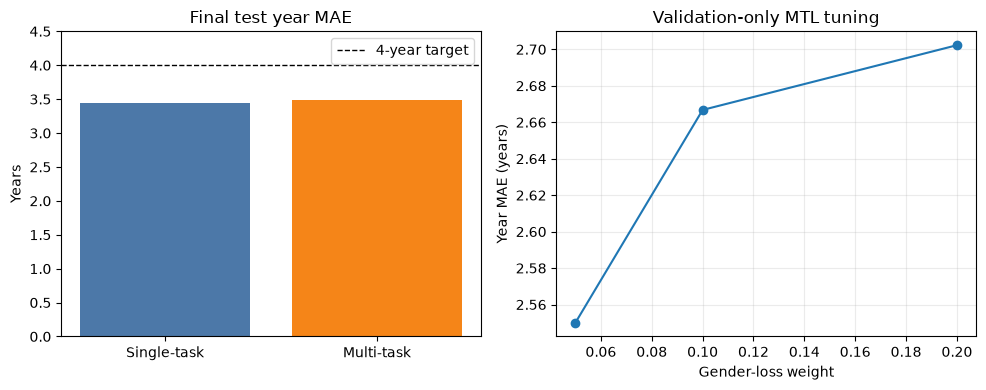

In [5]:
candidate_table = pd.DataFrame([
    {
        "auxiliary_weight": row["auxiliary_weight"],
        "validation_year_mae": row["best_validation"]["year_mae"],
        "validation_gender_accuracy": row["best_validation"]["gender_accuracy"],
    }
    for row in selection["all_multi_candidates"]
])
display(candidate_table)

result_table = pd.DataFrame([
    {"model": "Single-task", "test_year_mae": metrics["single"]["year_mae"], "gender_accuracy": np.nan, "gender_f1": np.nan},
    {"model": "Multi-task", "test_year_mae": metrics["multi"]["year_mae"], "gender_accuracy": metrics["multi"]["gender_accuracy"], "gender_f1": metrics["multi"]["gender_f1"]},
]).set_index("model")
display(result_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(result_table.index, result_table["test_year_mae"], color=["#4c78a8", "#f58518"])
axes[0].axhline(4.0, color="black", linestyle="--", linewidth=1, label="4-year target")
axes[0].set(title="Final test year MAE", ylabel="Years", ylim=(0, 4.5))
axes[0].legend()
axes[1].plot(candidate_table["auxiliary_weight"], candidate_table["validation_year_mae"], marker="o")
axes[1].set(title="Validation-only MTL tuning", xlabel="Gender-loss weight", ylabel="Year MAE (years)")
axes[1].grid(alpha=.25)
fig.tight_layout()
fig.savefig(FIGURES / "results_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

## Prediction diagnostics

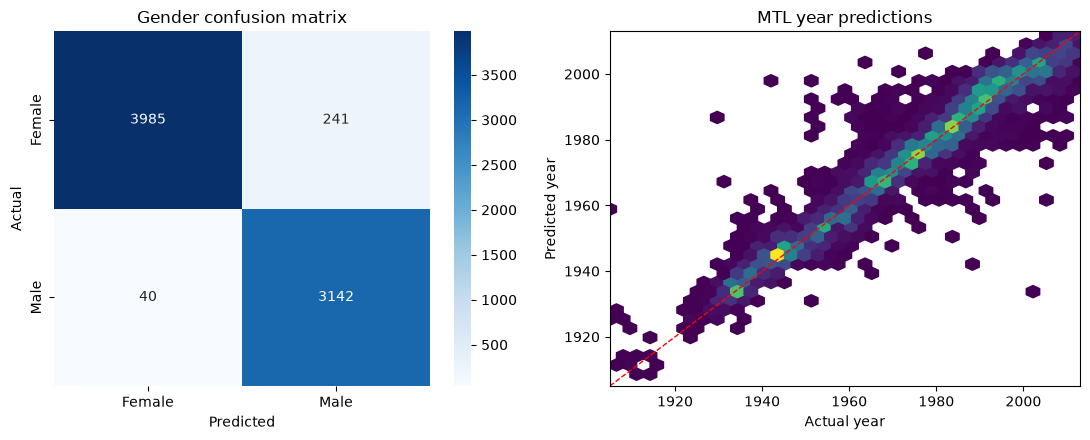

,path,target_year,single_predicted_year,multi_predicted_year,target_gender,multi_predicted_gender
5205,M/1966_Missouri_Kansas-City_Paseo_f-11-7.png,1966.0,1964.01,1963.64,1,1
4746,M/1977_South-Carolina_Charleston_Middleton_23-...,1977.0,1972.50,1974.87,1,1
1936,F/1939_Massachusetts_Plymouth_Plymouth_10-7.png,1939.0,1940.94,1940.89,0,0
4797,M/1971_Missouri_Kansas-City_Paseo_5-03.png,1971.0,1975.51,1976.72,1,1
2227,F/1990_California_San-Francisco_Abraham-Lincol...,1990.0,1991.38,1990.59,0,0
1155,F/1989_Massachusetts_Plymouth_Plymouth-North-S...,1989.0,1986.32,1985.37,0,0
2819,F/1949_Pennsylvania_Pittsburgh_David-B-Oliver_...,1949.0,1948.35,1944.95,0,0
3632,F/1940_Virginia_Arlington_Washington-Lee_f-6-1...,1940.0,1942.34,1941.68,0,0
3358,F/2008_Massachusetts_Plymouth_Plymouth-North_0...,2008.0,2004.09,2008.99,0,0
1528,F/1949_Pennsylvania_Pittsburgh_David-B-Oliver_...,1949.0,1949.06,1944.76,0,0


In [6]:
confusion = pd.crosstab(
    predictions["target_gender"].map({0: "Female", 1: "Male"}),
    predictions["multi_predicted_gender"].map({0: "Female", 1: "Male"}),
)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set(title="Gender confusion matrix", xlabel="Predicted", ylabel="Actual")
axes[1].hexbin(predictions["target_year"], predictions["multi_predicted_year"], gridsize=35, mincnt=1, cmap="viridis")
axes[1].plot([1905, 2013], [1905, 2013], "r--", linewidth=1)
axes[1].set(title="MTL year predictions", xlabel="Actual year", ylabel="Predicted year", xlim=(1905, 2013), ylim=(1905, 2013))
fig.tight_layout()
fig.savefig(FIGURES / "prediction_diagnostics.png", dpi=180, bbox_inches="tight")
plt.show()

sample_columns = ["path", "target_year", "single_predicted_year", "multi_predicted_year", "target_gender", "multi_predicted_gender"]
display(predictions.sample(10, random_state=1)[sample_columns].round(2))

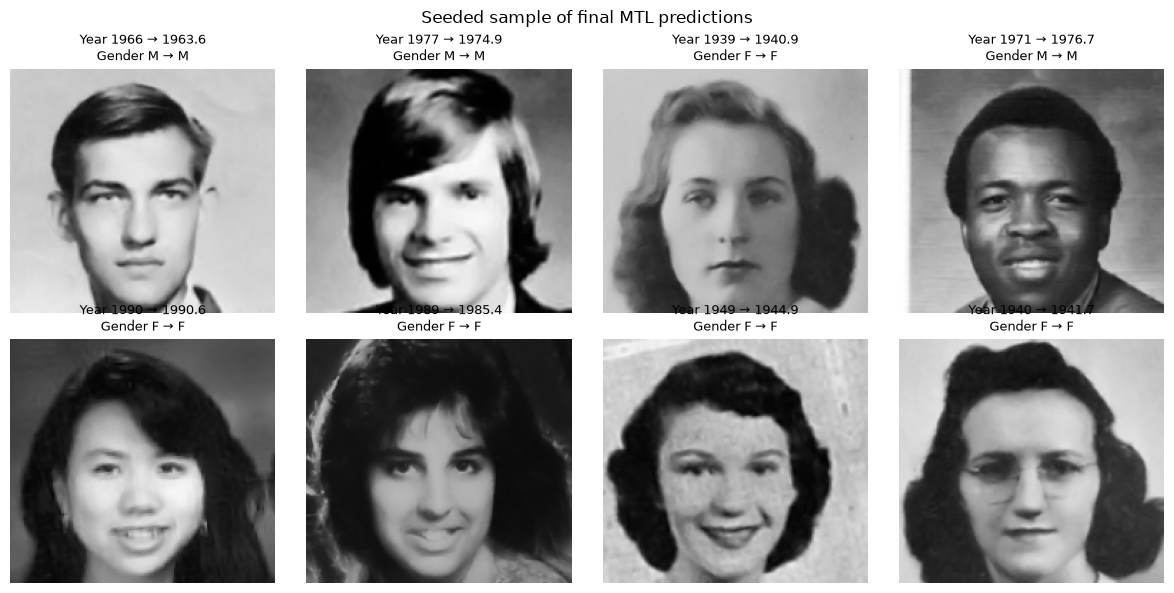

In [7]:
# Visual examples loaded from the compact archive database.
database = next((ROOT / "data").rglob("portraits.sqlite3"))
examples = predictions.sample(8, random_state=1)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
with sqlite3.connect(database) as connection:
    for ax, (_, row) in zip(axes.flat, examples.iterrows()):
        relative = "/".join(Path(row["path"]).parts[-2:])
        blob = connection.execute("SELECT data FROM images WHERE path = ?", (relative,)).fetchone()[0]
        import io
        ax.imshow(Image.open(io.BytesIO(blob)), cmap="gray")
        actual_gender = "M" if row["target_gender"] else "F"
        predicted_gender = "M" if row["multi_predicted_gender"] else "F"
        ax.set_title(f"Year {row['target_year']:.0f} → {row['multi_predicted_year']:.1f}\nGender {actual_gender} → {predicted_gender}", fontsize=9)
        ax.axis("off")
fig.suptitle("Seeded sample of final MTL predictions")
fig.tight_layout()
fig.savefig(FIGURES / "sample_predictions.png", dpi=180, bbox_inches="tight")
plt.show()